<a href="https://colab.research.google.com/github/Kush870/Unsupervised-Learning/blob/main/Country_Dataset_Problem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
X = pd.read_csv("Country-data.csv")

ohe = OneHotEncoder()
X_encoded = ohe.fit_transform(X[['country']])
print("Original Dataset Shape: ", X.shape)

pca = PCA(n_components = 2)

X_compressed = pca.fit_transform(X_encoded)

print("PCA Dataset Shape: ",X_compressed.shape)

X_reconstructed = pca.inverse_transform(X_compressed)

print("Reconstructed Dataset Shape: ", X_reconstructed.shape)


Original Dataset Shape:  (167, 10)
PCA Dataset Shape:  (167, 2)
Reconstructed Dataset Shape:  (167, 167)


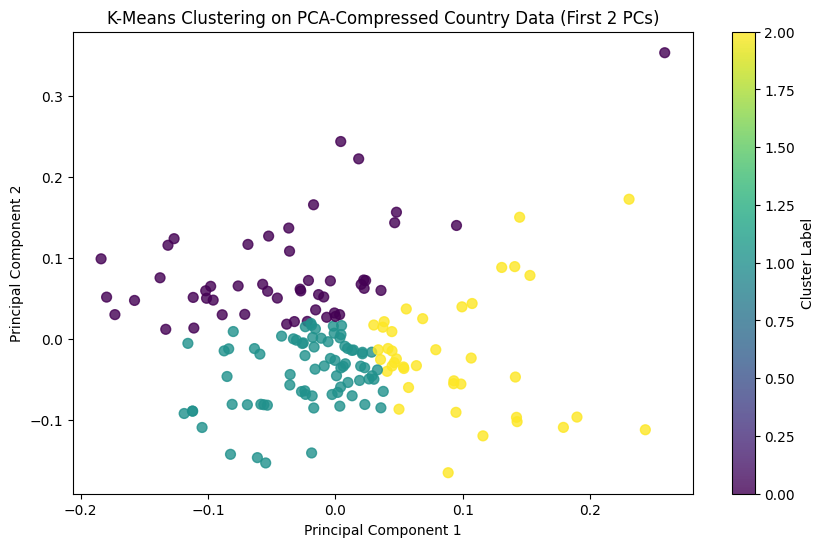

In [22]:
from sklearn.cluster import KMeans


k_means = KMeans(n_clusters=3, random_state=42)


clusters = k_means.fit_predict(X_compressed)


X['cluster'] = clusters


plt.figure(figsize=(10, 6))
plt.scatter(X_compressed[:, 0], X_compressed[:, 1], c=clusters, cmap='viridis', s=50, alpha=0.8)
plt.title('K-Means Clustering on PCA-Compressed Country Data (First 2 PCs)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster Label')
plt.show()